
# Titanic Survival: Exploratory Data Analysis

## 1. Project Overview

The sinking of the RMS Titanic in 1912 resulted in the loss of many lives.
This project explores the Titanic passenger dataset to understand which
passenger characteristics were associated with survival.

Using Python, Pandas, NumPy, Matplotlib, and Seaborn, we will inspect
the dataset, investigate data quality, explore passenger characteristics,
and visualize patterns related to survival.

### Objectives

- Understand the structure and quality of the dataset.
- Investigate missing values and duplicate records.
- Explore passenger characteristics such as age, gender, and passenger class.
- Analyze survival rates across different passenger groups.
- Investigate relationships between fare, passenger class, family size, and survival.
- Summarize key findings and acknowledge limitations.

### Key Questions

1. What proportion of passengers survived?
2. How did survival rates differ by gender and passenger class?
3. Was age associated with survival?
4. Did travelling with family relate to survival?
5. How did fare relate to survival, and how might passenger class help explain this relationship?

### Dataset

The analysis uses the Titanic training dataset from Kaggle's
[Titanic: Machine Learning from Disaster](https://www.kaggle.com/competitions/titanic/data)
competition.

The dataset contains passenger information, including age, sex,
passenger class, fare, family relationships, and survival status.


In [71]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [72]:

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)


## 2. Loading and Inspecting the Dataset

In this section, we load the Titanic dataset and inspect its
structure, dimensions, columns, and data types.

In [73]:
df= pd.read_csv("data/train.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [74]:
df.describe()


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [75]:
df.shape


(891, 12)

In [76]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


## 3. Data Quality Assessment

Before performing exploratory analysis, we examine the dataset
for missing values, duplicate records, and potential inconsistencies.

This helps us understand the limitations of the data and make
informed decisions during analysis.

In [77]:
missing_data=pd.DataFrame({
    "missing_values":df.isnull().sum(),
    "missing_percentage":((df.isnull().sum())/len(df))*100
})

missing_data=missing_data[missing_data["missing_percentage"]>0]
missing_data

,missing_values,missing_percentage
Age,177,19.865320
Cabin,687,77.104377
Embarked,2,0.224467


### 3.2 Checking for Duplicate Records

Duplicate records can affect statistical analysis by causing
certain observations to be counted more than once.

We check whether the dataset contains any completely duplicated rows.

In [78]:
df.duplicated().sum()

np.int64(0)

**Observation:** The dataset contains no completely duplicated
records. Therefore, no rows need to be removed due to exact duplication.

### 3.3 Checking Numerical Distributions

We examine numerical columns to identify unusual values,
unexpected ranges, and potential outliers.

Outliers are not automatically errors; they require further investigation.

In [79]:
df[["Age", "Fare", "SibSp", "Parch", "Pclass"]].describe()

,Age,Fare,SibSp,Parch,Pclass
count,714.000000,891.000000,891.000000,891.000000,891.000000
mean,29.699118,32.204208,0.523008,0.381594,2.308642
std,14.526497,49.693429,1.102743,0.806057,0.836071
min,0.420000,0.000000,0.000000,0.000000,1.000000
25%,20.125000,7.910400,0.000000,0.000000,2.000000
50%,28.000000,14.454200,0.000000,0.000000,3.000000
75%,38.000000,31.000000,1.000000,0.000000,3.000000
max,80.000000,512.329200,8.000000,6.000000,3.000000


**Observation:** The numerical columns do not contain negative values.
The minimum values appear valid for the selected variables.
No obvious invalid negative values were identified during this check.

In [80]:
print("Sex:", df["Sex"].unique())
print("Pclass:", df["Pclass"].unique())
print("Embarked:", df["Embarked"].unique())

Sex: <StringArray>
['male', 'female']
Length: 2, dtype: str
Pclass: [3 1 2]
Embarked: <StringArray>
['S', 'C', 'Q', nan]
Length: 4, dtype: str


### 3.4 Data Quality Summary

The initial data-quality assessment revealed the following:

1. **Missing Values:** Age contains 177 missing values (19.87%),
   Cabin contains 687 missing values (77.10%), and Embarked contains
   2 missing values (0.22%).

2. **Duplicate Records:** No completely duplicated rows were found.

3. **Numerical Values:** No negative values were found in the
   numerical columns examined.

4. **Categorical Values:** The observed categories in Sex, Pclass,
   and Embarked are consistent with the expected Titanic dataset
   categories.

These findings will guide our analysis. Missing values will be
considered when interpreting results, and unusual values will be
investigated rather than automatically removed.

## 4. Exploratory Data Analysis

In this section, we explore passenger characteristics and investigate
the factors associated with survival.

### 4.1 Overall Survival Distribution

We begin by examining the number and proportion of passengers
who survived and those who did not.


In [81]:
df["Survived"].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [82]:
survival_percentage=(df["Survived"].value_counts()/len(df))*100

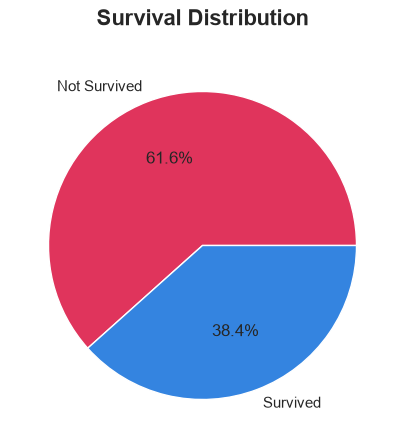

In [83]:


plt.figure(figsize=(5, 5))

survival_percentage.plot(kind="pie",
                        labels=["Not Survived" , "Survived"], 
                         autopct="%1.1f%%",
                          colors=["#e0345c" ,"#3484e0"] )

plt.title("Survival Distribution", 
          fontsize=16, 
          fontweight="bold",
          pad=20)
plt.show()


**Observations:**

1. Out of 891 passengers, 342 survived, while 549 did not survive.
2. Approximately 38.38% of passengers survived, whereas 61.62% lost their lives.
3. The number of passengers who did not survive was considerably higher than the number who survived.

**Conclusion:** The overall survival rate was relatively low, with more than 60% of the passengers losing their lives in the Titanic disaster.

### 4.2 Age Distribution

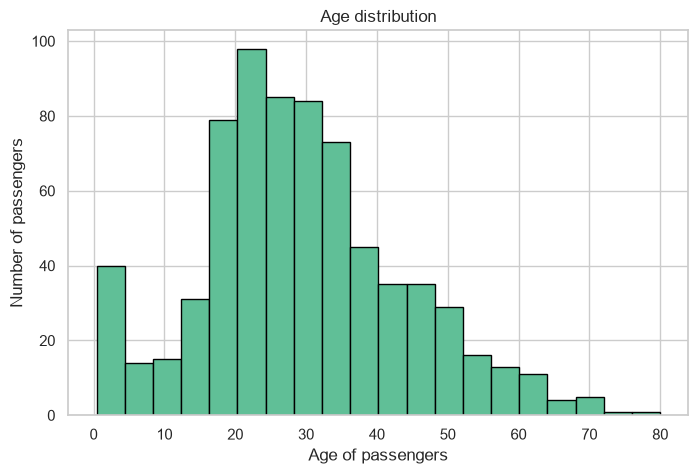

In [84]:
age_dist=df["Age"].plot(kind="hist", 
                      bins=20,
                      color="#60bf97",
                      edgecolor="black")
plt.xlabel("Age of passengers")
plt.ylabel("Number of passengers")
plt.title("Age distribution")
plt.show()

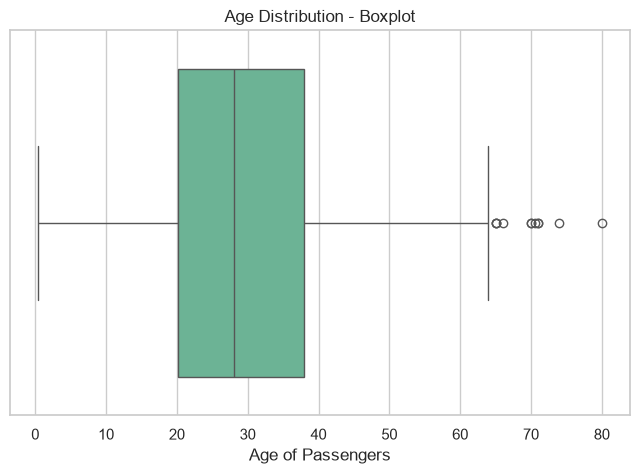

In [85]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x=df["Age"],
    color="#60bf97"
)

plt.title("Age Distribution - Boxplot")
plt.xlabel("Age of Passengers")
plt.show()

**Observations:**

1. The median age of passengers is approximately 28 years.
2. The middle 50% of passengers fall within the age range of approximately 20–38 years.
3. The non-outlier age range extends from approximately 0 to 65 years.
4. Several older passengers appear as potential outliers.

**Conclusion:** Most passengers were young adults, with a relatively small number of elderly passengers.

### 4.3 Fare Distribution 

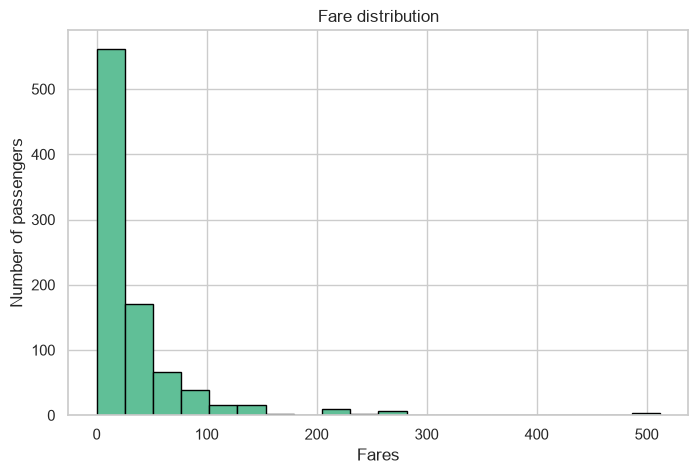

In [86]:
fare_dist=df["Fare"].plot(kind="hist", 
                      bins=20,
                      color="#60bf97",
                      edgecolor="black")
plt.xlabel("Fares")
plt.ylabel("Number of passengers")
plt.title("Fare distribution")
plt.show()

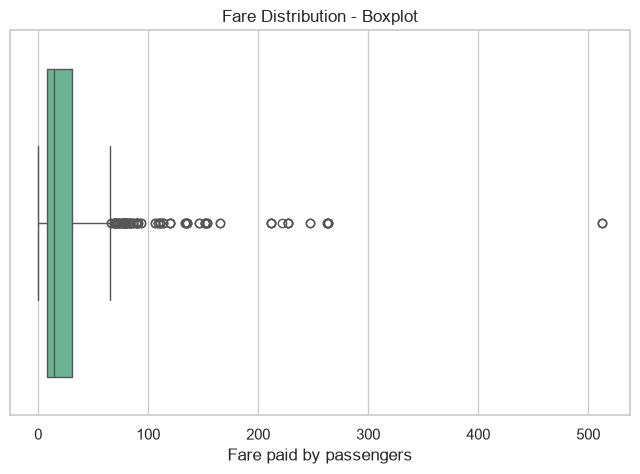

In [87]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x=df["Fare"],
    color="#60bf97"
)

plt.title("Fare Distribution - Boxplot")
plt.xlabel("Fare paid by passengers")
plt.show()

You can write this in your notebook:

Observations:
- Most passengers paid fares between 0 and 25.
- The fare distribution is positively skewed, with a long tail towards higher fares.
- A few passengers paid exceptionally high fares, with the maximum fare being approximately 512.33.
- These unusually high fares indicate considerable variation in ticket prices.
Conclusion: Most passengers travelled at relatively low fares, while a small number paid significantly higher amounts.
The boxplot confirms the presence of several high-fare outliers. The median fare is approximately 15, indicating that at least half of the passengers paid around 15 or less.


## 4.2 Bivariate Analysis

### 4.2.1 Survival vs Gender

In [88]:
sur_gen = df.groupby("Sex")["Survived"].sum()
print(sur_gen)


Sex
female    233
male      109
Name: Survived, dtype: int64


In [89]:
gender_survival_table = pd.crosstab(
    df["Sex"],
    df["Survived"]
)

gender_survival_table

Survived,0,1
Sex,,
female,81,233
male,468,109


In [90]:
sur_gen = df.groupby("Sex")["Survived"].mean()*100
print(sur_gen)


Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64


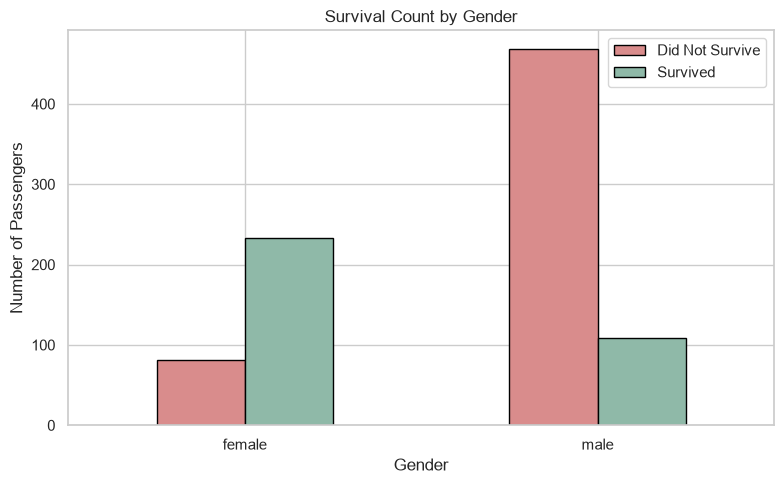

In [91]:
gender_survival_table.plot(
    kind="bar",
    figsize=(8, 5),
    color=["#D98C8C", "#8FB9A8"],
    edgecolor="black"
)

plt.title("Survival Count by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=0)
plt.legend(["Did Not Survive", "Survived"])
plt.tight_layout()
plt.show()

Observations:
1. Out of 314 female passengers, 233 survived and 81 did not survive.
2. Out of 577 male passengers, 109 survived and 468 did not survive.
3. Female passengers had a significantly higher survival rate (approximately 74.2%) compared to male passengers (approximately 18.9%).
4. The number of male passengers who did not survive was considerably higher than the number of female passengers who did not survive.
Conclusion: Gender appears to have had a strong association with survival on the Titanic. Female passengers were considerably more likely to survive than male passengers.

### 4.2.2 Survival vs Pclass

In [92]:
Pclass_survival_table = pd.crosstab(
    df["Pclass"],
    df["Survived"]
)

Pclass_survival_table

Survived,0,1
Pclass,,
1,80,136
2,97,87
3,372,119


In [93]:
df.groupby("Pclass")["Survived"].mean()*100

Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64

In [94]:
Pclass_survival_table=pd.crosstab(
    df["Pclass"], 
    df["Survived"]
)
Pclass_survival_table

Survived,0,1
Pclass,,
1,80,136
2,97,87
3,372,119


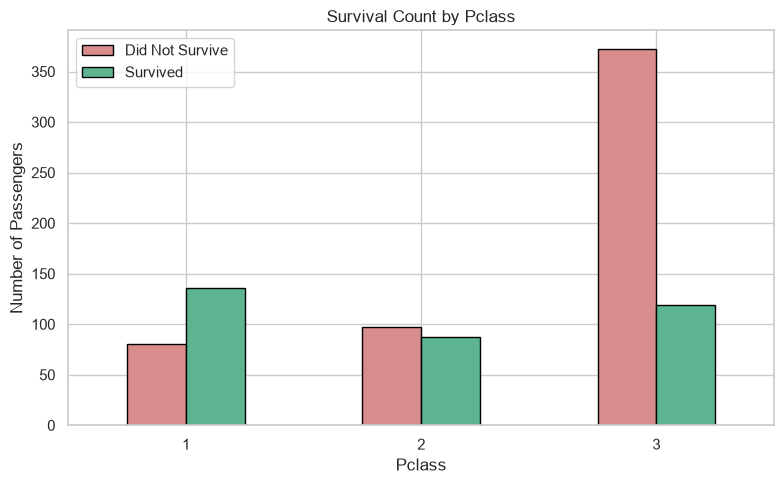

In [95]:
Pclass_survival_table.plot(
    kind="bar",
    figsize=(8, 5),
    color=["#D98C8C", "#5cb590" ,"#679ec7"],
    edgecolor="black"
)

plt.title("Survival Count by Pclass")
plt.xlabel("Pclass")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=0)
plt.legend(["Did Not Survive", "Survived"])
plt.tight_layout()
plt.show()

Observations:
1. First-class passengers had the highest survival rate (approximately 63%).
2. Second-class passengers had a survival rate of approximately 47%.
3. Third-class passengers had the lowest survival rate (approximately 24%).
4. Survival rates decreased from first class to third class.
Conclusion: Passenger class was strongly associated with survival. First-class passengers were more likely to survive, while third-class passengers had the lowest survival rate.

Pclass_survival_table = pd.crosstab(
    df["Pclass"],
    df["Survived"]
)

Pclass_survival_table

### 4.3.3 Age vs Survival

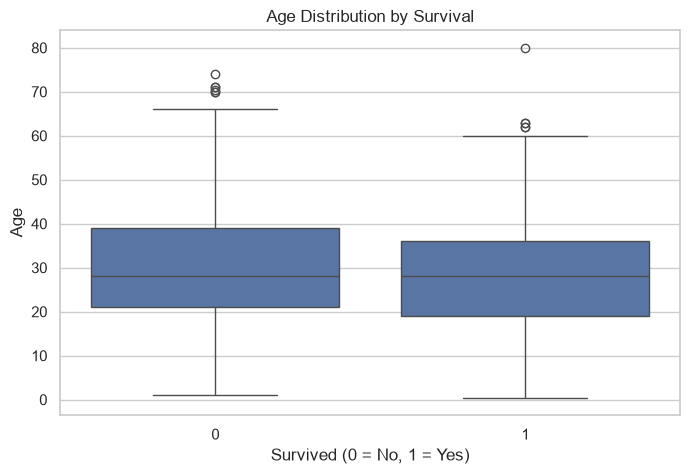

In [96]:
sns.boxplot(x="Survived", y="Age", data=df)
plt.title("Age Distribution by Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Age")
plt.show()

In [97]:
df.groupby("Survived")["Age"].mean()

Survived
0    30.626179
1    28.343690
Name: Age, dtype: float64

In [98]:
df.groupby("Survived")["Age"].median()

Survived
0    28.0
1    28.0
Name: Age, dtype: float64

Observations
- Passengers who survived were slightly younger on average (28.34 years) than those who did not survive (30.63 years).
- Both groups had the same median age of 28 years.
- The age distributions overlap considerably, indicating that passengers of similar ages experienced different survival outcomes.
- Therefore, age may have influenced survival, but age alone cannot explain or reliably predict survival.
Conclusion: Age appears to have had some influence on survival, but its relationship with survival is not strong enough to establish it as the sole determining factor. Other features, such as gender and passenger class, may also have played important roles.

### 4.3.4 Family Size vs Survival 

In [99]:
df["family_size"]=pd.DataFrame(df["SibSp"]+df["Parch"]+1)

In [100]:
sur_fam=df.groupby("family_size")["Survived"].mean()*100
sur_fam

family_size
1     30.353818
2     55.279503
3     57.843137
4     72.413793
5     20.000000
6     13.636364
7     33.333333
8      0.000000
11     0.000000
Name: Survived, dtype: float64

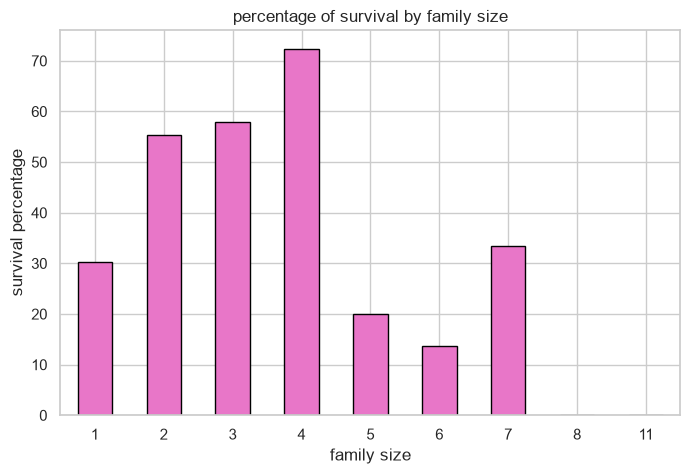

In [101]:
sur_fam.plot(kind="bar" , 
             color="#e876c8", 
             edgecolor="black")
plt.title("percentage of survival by family size")
plt.xlabel("family size")
plt.ylabel("survival percentage")
plt.xticks(rotation =0)
plt.show()

In [102]:
sur_fam=df.groupby("family_size")["Survived"].sum()
sur_fam

family_size
1     163
2      89
3      59
4      21
5       3
6       3
7       4
8       0
11      0
Name: Survived, dtype: int64

In [103]:
sur_fam=df.groupby("family_size").size()
sur_fam

family_size
1     537
2     161
3     102
4      29
5      15
6      22
7      12
8       6
11      7
dtype: int64

Observations
1. Passengers travelling alone (family size 1) had a survival rate of approximately 30.35%, compared with 55.28% for family size 2 and 57.84% for family size 3.

2. Family size 4 had the highest survival rate of approximately 72.41%. However, this group contained only 29 passengers, so the result should be interpreted cautiously.

3. Survival rates were considerably lower for family sizes 5 and 6, at 20% and 13.64%, respectively.

4. Family size 7 had a survival rate of 33.33%, but this was based on just 12 passengers.

5. Family sizes 8 and 11 had no survivors in the dataset. These groups contained only 6 and 7 passengers, respectively.

6. The passenger distribution shows that most people travelled alone (537 passengers), while larger families were relatively uncommon.
Conclusion
The analysis suggests that passengers travelling with small families (2–4 members) generally had higher survival rates than those travelling alone. Very large families tended to have lower survival rates, although the small number of observations in these groups makes the percentages less reliable.

Family size appears to be associated with survival, but it cannot independently explain survival outcomes.

### 4.3.5 Fare vs Survival

In [104]:
fare_sur=df.groupby("Survived")["Fare"].mean()
fare_sur

Survived
0    22.117887
1    48.395408
Name: Fare, dtype: float64

In [105]:
fare_sur=df.groupby("Survived")["Fare"].median()
fare_sur

Survived
0    10.5
1    26.0
Name: Fare, dtype: float64

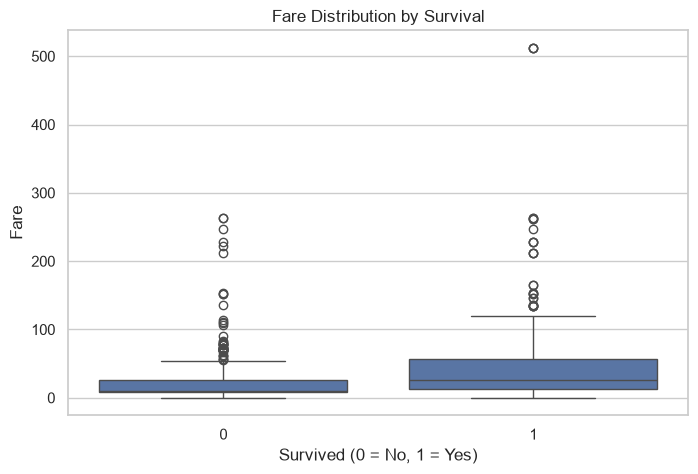

In [106]:
sns.boxplot(x="Survived", y="Fare", data=df)
plt.title("Fare Distribution by Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Fare")
plt.show()

Observations
1. The average fare paid by survivors was approximately 48.40, compared with 22.12 for non-survivors.
2. The median fare for survivors was 26, while for non-survivors it was 10.50.
3. Both the mean and median fares were considerably higher for survivors, suggesting an association between higher ticket fares and better survival outcomes.
4. The boxplot shows a wider interquartile range for survivors, indicating greater variation in their fares.
5. Both groups contain several high-fare outliers, with the highest fare (approximately 512) belonging to a survivor.
6. Despite this difference, the distributions overlap, showing that paying a higher fare did not guarantee survival.
Conclusion
Passengers who survived generally paid higher fares than those who did not survive. This suggests that fare was associated with survival outcomes. However, this relationship may partly be explained by passenger class, as first-class passengers generally paid higher fares and had better survival rates.

### 4.3.6 Embarked vs survival

In [107]:
port_sur=df.groupby("Embarked")["Survived"].mean()*100
port_sur

Embarked
C    55.357143
Q    38.961039
S    33.695652
Name: Survived, dtype: float64

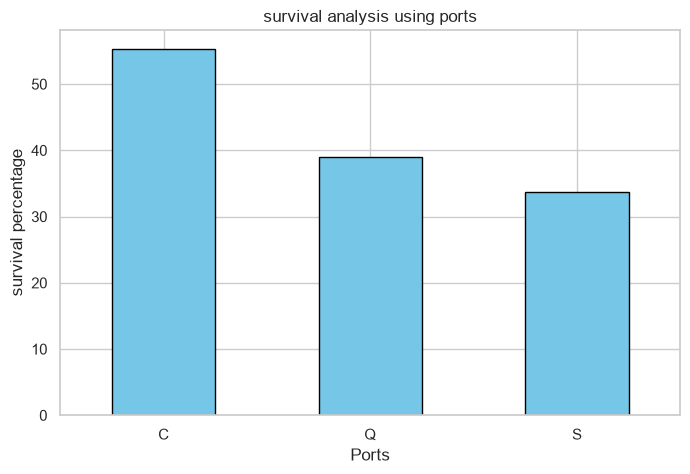

In [108]:
port_sur.plot(kind="bar" ,
              color="#76c6e8" , 
              edgecolor="black")
plt.title("survival analysis using ports")
plt.xlabel("Ports")
plt.ylabel("survival percentage")
plt.xticks(rotation=0)
plt.show()

Observations
1. Passengers who embarked at Cherbourg (C) had the highest survival rate of approximately 55.36%.
2. Passengers from Queenstown (Q) had a survival rate of approximately 38.96%.
3. Passengers from Southampton (S) had the lowest survival rate of approximately 33.70%.
4. The survival rate at Cherbourg was considerably higher than at Southampton and Queenstown.
5. These differences suggest that the port of embarkation was associated with survival outcomes.
Conclusion
Passengers embarking at Cherbourg had a higher survival percentage than those embarking at Queenstown and Southampton. However, the port itself may not have directly influenced survival. The difference could partly be explained by passenger class, as the distribution of first-, second-, and third-class passengers varied across ports.

### 4.3.7 Cabin Availability vs Survival

In [109]:
df["HasCabin"] = df["Cabin"].notna().astype(int)

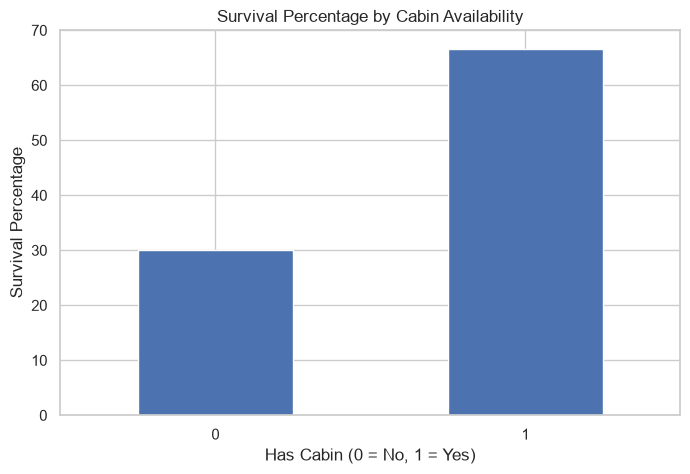

In [110]:
df.groupby("HasCabin")["Survived"].mean().mul(100).plot(kind="bar")

plt.title("Survival Percentage by Cabin Availability")
plt.xlabel("Has Cabin (0 = No, 1 = Yes)")
plt.ylabel("Survival Percentage")
plt.xticks(rotation=0)
plt.show()

In [111]:
df.groupby("HasCabin")["Survived"].agg(["mean", "count"])

,mean,count
HasCabin,,
0,0.299854,687
1,0.666667,204


Observations
1. Passengers with recorded cabin information had a survival rate of approximately 66.67%.
2. Passengers without recorded cabin information had a considerably lower survival rate of approximately 29.99%.
3. The survival rate of passengers with cabin information was more than twice that of passengers without it.
4. Out of 891 passengers, 687 (approximately 77.1%) had missing cabin information, while only 204 had recorded cabin details.
5. This suggests a strong association between cabin availability and survival outcomes.
Conclusion
Passengers with recorded cabin information had significantly higher survival rates than those without it. However, this does not necessarily mean that having cabin information caused better survival. Cabin availability may be related to passenger class, as first-class passengers were more likely to have recorded cabin details.

## 5.00 Multivariate Analysis

In [112]:
survival_gender_class = pd.pivot_table(
    df,
    index="Sex",
    columns="Pclass",
    values="Survived",
    aggfunc="mean"
) * 100

survival_gender_class

Pclass,1,2,3
Sex,,,
female,96.808511,92.105263,50.000000
male,36.885246,15.740741,13.544669


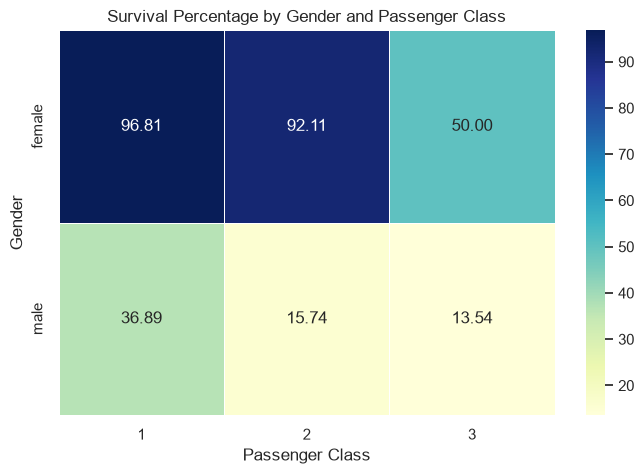

In [113]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    survival_gender_class,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Survival Percentage by Gender and Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Gender")
plt.show()

Observations
1. Women had higher survival rates than men across all three passenger classes.
2. First-class women had the highest survival rate at approximately 96.81%.
3. Second-class women also had a very high survival rate of approximately 92.11%.
4. Third-class women's survival rate dropped to 50%, considerably lower than women in first and second class.
5. Male survival rates were much lower across all classes:
   - First class: 36.89%
   - Second class: 15.74%
   - Third class: 13.54%
6. First-class men had a higher survival rate than second- and third-class men.

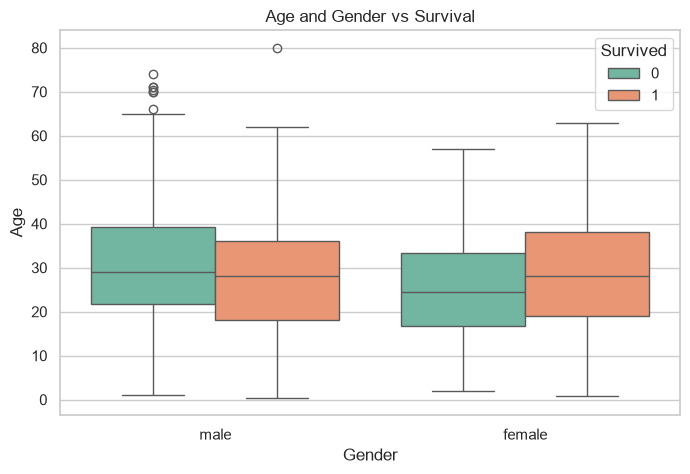

In [114]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Sex",
    y="Age",
    hue="Survived",
    palette="Set2"
)

plt.title("Age and Gender vs Survival")
plt.xlabel("Gender")
plt.ylabel("Age")
plt.legend(title="Survived")
plt.show()

Observations
1. Female survivors generally appear to be older than female non-survivors.
2. Male survivors generally appear to be younger than male non-survivors.
3. This suggests that age had different associations with survival for males and females.
4. Female survivors show a relatively wide age distribution, indicating that women across a broader range of ages survived.
5. Among males, survival appears more concentrated among younger passengers.
Conclusion
The relationship between age and survival was not uniform across genders. While younger males appeared more likely to survive, female survivors included passengers across a wider age range. This reinforces the importance of studying multiple features together rather than analyzing each feature independently.

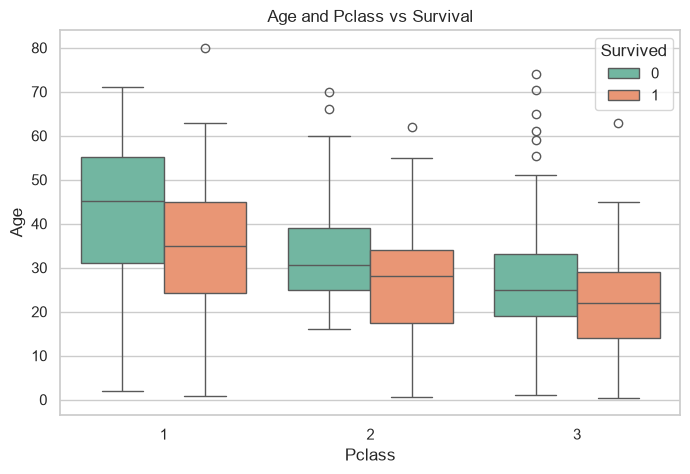

In [115]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Pclass",
    y="Age",
    hue="Survived",
    palette="Set2"
)

plt.title("Age and Pclass vs Survival")
plt.xlabel("Pclass")
plt.ylabel("Age")
plt.legend(title="Survived")
plt.show()

In [116]:
df.groupby(["Pclass", "Survived"])["Age"].agg(["mean", "median", "count"])

mean  median  count
Pclass Survived                          
1      0         43.695312   45.25     64
       1         35.368197   35.00    122
2      0         33.544444   30.50     90
       1         25.901566   28.00     83
3      0         26.555556   25.00    270
       1         20.646118   22.00     85

observations
1. In all three passenger classes, survivors had a lower average age than non-survivors.
2. The difference in average age between survivors and non-survivors was greatest in first class (approximately 8.33 years).
3. The average age of passengers decreased from first class to third class, for both survivors and non-survivors.
4. Age appears to be associated with survival across all three classes, though this analysis alone cannot establish causation.

## Key Findings
1. Overall Survival: Out of 891 passengers, only 342 survived, giving an overall survival rate of 38.38%.

2. Gender and Survival: Female passengers had a much higher survival rate (74.2%) than male passengers (18.9%).

3. Passenger Class: First-class passengers had the highest survival rate (63%), followed by second class (47.3%) and third class (24.2%).

4. Age and Survival: Survivors were slightly younger on average than non-survivors.

5. Family Size and Fare: Passengers travelling in small family groups and those who paid higher fares generally had better survival rates.

6. Multivariate Analysis – Gender and Class: Females had higher survival rates across all classes. First-class females had the highest survival rate (96.81%), while third-class males had the lowest (13.54%).

7. Multivariate Analysis – Age: Survivors were younger than non-survivors across all three classes. Age patterns also differed between male and female survivors.

8. Other Factors: Passengers with recorded cabin information and those embarking at Cherbourg showed higher survival rates.

Overall: Gender and passenger class showed particularly strong associations with survival. The multivariate analysis confirmed that survival patterns varied when multiple passenger characteristics were considered together. These are associations, not proof of causation.

## Limitations

Missing Values: The dataset contains missing values in Age, Cabin, and Embarked columns, which may affect some analyses.



Limited Features: The dataset contains only a limited set of passenger details and may not capture all factors that influenced survival.



Observational Data: The analysis identifies relationships between passenger characteristics and survival but cannot establish cause-and-effect relationships.



Unequal Group Sizes: Some groups, such as passengers travelling in larger families, have fewer observations, making their survival percentages less reliable.



Potentially Related Features: Factors such as passenger class, fare, and cabin information may be related to one another, making it difficult to isolate their individual associations with survival.

## 

This exploratory data analysis of the Titanic dataset helped identify the passenger characteristics associated with survival. Gender and passenger class showed the strongest relationships with survival, while age, family size, fare, cabin information, and port of embarkation also revealed interesting patterns.

The multivariate analysis further showed that survival patterns varied when multiple passenger characteristics were considered together. Overall, this project provided useful insights into the dataset through data cleaning, visualization, and statistical analysis.





## Conclusion

This exploratory data analysis of the Titanic dataset helped identify the passenger characteristics associated with survival. Gender and passenger class showed the strongest relationships with survival, while age, family size, fare, cabin information, and port of embarkation also revealed interesting patterns.

The multivariate analysis further showed that survival patterns varied when multiple passenger characteristics were considered together. Overall, this project provided useful insights into the dataset through data cleaning, visualization, and statistical analysis.

